# Demand shocks by size

How the optimal policy response scales with the **magnitude** of the demand shock. The model is
the corrected one from [`new_fixed.ipynb`](new_fixed.ipynb) — physical consumption, a rate matrix
that keeps its history, and an optimised rate sequence rather than an enumeration — with `D_SHOCK`
promoted from a fixed `0.01` to the swept parameter. Calibration and the loss
$\sum_t c_t^2+\sum_t\pi_t^2$ are unchanged, so single-size results here reproduce that notebook.

The model is log-linear, so the *fixed-rate* response is proportional in the shock by
construction: $c_0=-D/\gamma$ and nothing else moves. That is checked below and then set aside.
Everything interesting is in the policy response, and it splits by whether firms have time to
build:

1. **Without time to build the first best is exactly attainable**, via $i_0=\rho-D$ — a
   one-for-one cut — until $D$ reaches $\rho=1\%$ and the bound $i\ge 0$ binds. Past that the
   planner spreads the stimulus it cannot deliver, and the residual has a closed form,
   $\text{peak}|c|=(D-\rho)/2\gamma$, exact up to $D=3\rho$.
2. **The kinks keep coming.** Each time the shock grows enough, one more period is pinned at the
   bound. The thresholds are at $D/\rho = 1,\,3,\,6,\,\approx\!10$ — so the loss is piecewise
   quadratic in the shock size, not quadratic.
3. **Time to build halves the pass-through.** When firms discount over a production lag the rate
   feeds into prices, so cutting is no longer free: the planner moves $i_0$ only $0.535$ for every
   $1$ of shock, overshoots above $\rho$ afterwards, and never reaches the first best at any size.
   The bound therefore binds *later* — at $D=1.87\%$ rather than $1\%$.

In [1]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from scipy.optimize import minimize

/Users/samuelzhao/anaconda3/lib/python3.10/site-packages/pandas/core/arrays/masked.py:61: UserWarning: Pandas requires version '1.3.6' or newer of 'bottleneck' (version '1.3.5' currently installed).
  from pandas.core import (


## 1. Parameters and calibration

Unchanged from `new_fixed.ipynb`. `D_SHOCK` is kept only as the baseline that reproduces it.

In [2]:
INVENTORY_TO_COGS_SCALING = 36.5
NOMINAL_INTEREST_RATE = 0.01
sigma = 5
gamma = 1.0
eta = 2.0
PHI_YA = (1 + eta) / (gamma + eta)

beta  = 1 / (1.0 + NOMINAL_INTEREST_RATE)
beta1 = 1 / (1.0 + NOMINAL_INTEREST_RATE * np.exp(30 / (INVENTORY_TO_COGS_SCALING * 0.9)))
beta_hh = beta
rho = 1 / beta_hh - 1

T = 30
PI_WEIGHT = 1.0
BOUNDS = (0.0, 0.05)
L_FREE = 8                                     # free policy periods; horizon check in section 3

D_SHOCK  = 0.01                                # baseline, matches new_fixed.ipynb
D_SIZES  = [0.004, 0.010, 0.020, 0.030]        # sizes carried through the figures
                                               # (must be a subset of D_GRID, section 4)

print(f'gamma={gamma}, eta={eta}, phi_ya={PHI_YA}, rho={rho:.6f}')
print(f'the bound i >= 0 can deliver at most rho = {100*rho:.2f}% of stimulus in one period')

gamma=1.0, eta=2.0, phi_ya=1.0, rho=0.010000
the bound i >= 0 can deliver at most rho = 1.00% of stimulus in one period


In [3]:
data = pd.read_csv('APP_data_usa_goods.csv', index_col=0, parse_dates=True)
data_tau = data['invtCogsRatio'] * INVENTORY_TO_COGS_SCALING / (30 * 0.1)

c_list = np.linspace(0, 0.99, 1000)
tau_diff = np.zeros(1000)
for i, cv in enumerate(c_list):
    if beta * cv <= 1e-10:
        tau_diff[i] = np.inf
        continue
    Nn = -(data_tau) - 1 / np.log(beta * cv)
    t1 = -1 / np.log(beta  * cv) - Nn;  t1[t1 < 0] = 0
    t2 = -1 / np.log(beta1 * cv) - Nn;  t2[t2 < 0] = 0
    tau_diff[i] = np.mean(np.abs(t1 - t2))
optimal_c_value = np.min(c_list[np.where(np.abs(tau_diff - 1) ==
                                         np.min(np.abs(tau_diff - 1)))[0]])

N = -data_tau - 1 / np.log(beta * optimal_c_value)
tau = -1 / np.log(beta * optimal_c_value) - N
tau[tau < 0] = 0
tf, tc = np.floor(tau), np.ceil(tau)
pc = (beta * optimal_c_value)**tc * (tc + N)
pf = (beta * optimal_c_value)**tf * (tf + N)
tau[(pc - pf) > 0] = tc[(pc - pf) > 0]
tau[(pc - pf) < 0] = tf[(pc - pf) < 0]
tau[tau < 0] = 0

tvals   = tau.astype(int).to_numpy()
N_array = np.array(N)
NFIRMS  = len(tvals)
Z_PHYS  = optimal_c_value * (tvals + N_array)

print(f'c = {optimal_c_value:.7f}   mean tau = {tau.mean():.4f}   firms = {NFIRMS}')

/var/folders/26/bmvk0hrd5xbgcvl_s6s42rf80000gn/T/ipykernel_16841/1709176470.py:1: UserWarning: Could not infer format, so each element will be parsed individually, falling back to `dateutil`. To ensure parsing is consistent and as-expected, please specify a format.
  data = pd.read_csv('APP_data_usa_goods.csv', index_col=0, parse_dates=True)


c = 0.9018018   mean tau = 2.8885   firms = 269


## 2. The model, with the shock size as an argument

`solve` is `new_fixed.ipynb`'s, with `D` passed in instead of read off the global `D_SHOCK`.
There is no TFP shock anywhere in this notebook, so `A_PATTERN` and the staggering matrix drop
out entirely — the only thing moving is the demand shifter and the rate.

In [4]:
def rate_matrix(r, T=T, truncated=False):
    '''Row t = the rates a firm delivering at t discounts over, most recent first.'''
    L = len(r)
    ip = np.ones(T) * rho
    ip[:L] = np.asarray(r, float)
    irl = np.ones((T, T)) * rho
    if truncated:                              # the original's construction
        blk = np.full((L, L), rho)
        for i in range(L):
            blk[i, :i + 1] = np.asarray(r, float)[i::-1]
        irl[0:L, :L] = blk
    else:                                      # corrected: rows keep their own history
        for t in range(T):
            for k in range(T):
                irl[t, k] = ip[t - k] if t - k >= 0 else rho
    return irl


def aggregates(r, T=T, time_to_build=True, truncated=False):
    '''(a_nat, d, pi) -- measured TFP, its discount content, and inflation.'''
    irl = rate_matrix(r, T, truncated)
    ce = np.ones((T, T + 1))
    ce[:, 1:] = np.cumprod(1.0 / (1.0 + irl), axis=1)
    tv = tvals if time_to_build else np.zeros_like(tvals)
    tprod = ce[:, tv] * Z_PHYS

    A_til = np.sum(tprod**(sigma - 1), axis=1)**(1 / (sigma - 1))
    Z_t   = np.sum(Z_PHYS**(sigma - 1) * np.ones((T, 1)), axis=1)**(1 / (sigma - 1))

    a_nat = np.log(A_til) - np.log(A_til)[-1]
    d     = np.log(A_til) - np.log(Z_t); d = d - d[-1]
    pi    = np.zeros(T); pi[1:] = -(a_nat[1:] - a_nat[:-1])       # P = 1/Atil
    return a_nat, d, pi


def solve(r, D, T=T, time_to_build=True, truncated=False):
    '''Euler equation, then consumption = gap + natural level, physically valued.'''
    a_nat, d, pi = aggregates(r, T, time_to_build, truncated)
    ip = np.ones(T) * rho
    ip[:len(r)] = np.asarray(r, float)
    dem = np.zeros(T); dem[0] = D
    pi_fwd = np.r_[pi[1:], 0.0]

    x = np.zeros(T + 1)
    for t in range(T - 1, -1, -1):
        x[t] = x[t + 1] - (1.0 / gamma) * (ip[t] - pi_fwd[t] - rho + dem[t])
    x = x[:T]

    c_meas = x + PHI_YA * a_nat
    return dict(c=c_meas - d, c_meas=c_meas, x=x, pi=pi, a=a_nat, d=d, i=ip)


def loss(r, D, time_to_build=True, truncated=False, w=PI_WEIGHT):
    s = solve(r, D, T, time_to_build, truncated)
    return float(np.sum(s['c']**2) + w * np.sum(s['pi']**2))


SEEDS = [lambda L: np.ones(L) * rho,
         lambda L: np.linspace(0.005, 0.015, L),
         lambda L: np.full(L, 0.005)]


def optimal(D, L=L_FREE, time_to_build=True, w=PI_WEIGHT):
    '''Best rate sequence over L free periods, three starts, L-BFGS-B on [0, 5%].'''
    best = None
    for seed in SEEDS:
        res = minimize(lambda r: loss(r, D, time_to_build, w=w), seed(L),
                       method='L-BFGS-B', bounds=[BOUNDS] * L,
                       options={'maxiter': 40000, 'ftol': 1e-20, 'gtol': 1e-16})
        if best is None or res.fun < best.fun:
            best = res
    return best.x.copy(), solve(best.x, D, T, time_to_build)

### The fixed-rate response is proportional by construction

With the rate held at $\rho$ the shifter enters only the Euler recursion, and nothing feeds back:
$a^{nat}$, $d$ and $\pi$ are functions of the rate path alone. Rolling the recursion back from
$x_T=0$ leaves $c_0=-D/\gamma$ and $c_t=0$ for $t\ge1$, at any magnitude. This is what makes the
size sweep a question about *policy* rather than about the shock.

In [5]:
print(f'{"D":>7}{"ttb":>7}{"c_0":>12}{"-D/gamma":>12}{"max|c_t|, t>0":>16}{"max|pi|":>11}')
print('-' * 65)
for D in [0.005, 0.01, 0.02, 0.04]:
    for ttb in [False, True]:
        s = solve(np.ones(3) * rho, D, time_to_build=ttb)
        assert np.isclose(s['c'][0], -D / gamma) and np.allclose(s['c'][1:], 0)
        print(f'{100*D:>6.1f}%{str(ttb):>7}{s["c"][0]:>12.7f}{-D/gamma:>12.7f}'
              f'{np.max(np.abs(s["c"][1:])):>16.2e}{np.max(np.abs(s["pi"])):>11.2e}')

print('\nc_0 = -D/gamma exactly, everything else identically zero, with or without time to build')

      D    ttb         c_0    -D/gamma   max|c_t|, t>0    max|pi|
-----------------------------------------------------------------
   0.5%  False  -0.0050000  -0.0050000        0.00e+00   0.00e+00
   0.5%   True  -0.0050000  -0.0050000        0.00e+00   0.00e+00
   1.0%  False  -0.0100000  -0.0100000        0.00e+00   0.00e+00
   1.0%   True  -0.0100000  -0.0100000        0.00e+00   0.00e+00
   2.0%  False  -0.0200000  -0.0200000        0.00e+00   0.00e+00
   2.0%   True  -0.0200000  -0.0200000        0.00e+00   0.00e+00
   4.0%  False  -0.0400000  -0.0400000        0.00e+00   0.00e+00
   4.0%   True  -0.0400000  -0.0400000        0.00e+00   0.00e+00

c_0 = -D/gamma exactly, everything else identically zero, with or without time to build


## 3. Horizon check

`new_fixed.ipynb` escalates `L` until the loss stops improving. Doing that inside a size sweep is
expensive, so `L` is fixed at 8; this confirms that is enough.

In [6]:
print(f'{"ttb":>7}{"L":>4}{"loss at D=2%":>18}{"i[:3] (%)":>26}')
print('-' * 55)
for ttb in [False, True]:
    for L in [4, 6, 8, 10, 12]:
        r, s = optimal(0.02, L=L, time_to_build=ttb)
        print(f'{str(ttb):>7}{L:>4}{np.sum(s["c"]**2) + np.sum(s["pi"]**2):>18.6e}'
              f'{str(np.round(100 * r[:3], 4)):>26}')
    print()
print('L = 8 is converged to four significant figures; L = 12 moves the loss by ~0.04%')

    ttb   L      loss at D=2%                 i[:3] (%)
-------------------------------------------------------


  False   4      5.000000e-05             [0.  0.5 1. ]


  False   6      5.000000e-05             [0.  0.5 1. ]


  False   8      5.000000e-05             [0.  0.5 1. ]


  False  10      5.000000e-05             [0.  0.5 1. ]


...

   True   4      5.442411e-05    [0.     1.3049 1.0204]


   True   6      5.419309e-05    [0.     1.3045 1.019 ]


   True   8      5.397959e-05    [0.     1.3027 1.0182]


   True  10      5.396128e-05    [0.     1.3025 1.0179]


   True  12      5.395758e-05    [0.     1.3025 1.0178]

L = 8 is converged to four significant figures; L = 12 moves the loss by ~0.04%


## 4. Optimal policy by shock size

In [7]:
D_GRID = np.array([0.001, 0.002, 0.004, 0.006, 0.008, 0.010, 0.012,
                   0.014, 0.016, 0.018, 0.020, 0.025, 0.030])

sweep = {}
for ttb in [False, True]:
    for D in D_GRID:
        r, s = optimal(D, time_to_build=ttb)
        sweep[(ttb, D)] = (r, s)

print(f'{"D":>7}{"i_0 no ttb":>13}{"rho - D":>11}{"i_0 ttb":>11}{"i_1 ttb":>10}'
      f'{"peak|c| no ttb":>17}{"peak|c| ttb":>14}{"peak|pi| ttb":>15}')
print('-' * 98)
for D in D_GRID:
    r0, s0 = sweep[(False, D)]
    r1, s1 = sweep[(True, D)]
    print(f'{100*D:>6.1f}%{100*r0[0]:>12.4f}%{100*(rho-D):>10.4f}%{100*r1[0]:>10.4f}%'
          f'{100*r1[1]:>9.4f}%{100*np.max(np.abs(s0["c"])):>16.4f}%'
          f'{100*np.max(np.abs(s1["c"])):>13.4f}%{100*np.max(np.abs(s1["pi"])):>14.4f}%')

      D   i_0 no ttb    rho - D    i_0 ttb   i_1 ttb   peak|c| no ttb   peak|c| ttb   peak|pi| ttb
--------------------------------------------------------------------------------------------------
   0.1%      0.9000%    0.9000%    0.9464%   1.0167%          0.0000%       0.0131%        0.0227%
   0.2%      0.8000%    0.8000%    0.8929%   1.0333%          0.0000%       0.0263%        0.0453%
   0.4%      0.6000%    0.6000%    0.7858%   1.0667%          0.0000%       0.0526%        0.0906%
   0.6%      0.4000%    0.4000%    0.6788%   1.1001%          0.0000%       0.0789%        0.1359%
   0.8%      0.2000%    0.2000%    0.5718%   1.1336%          0.0000%       0.1053%        0.1812%
   1.0%      0.0000%    0.0000%    0.4648%   1.1671%          0.0000%       0.1318%        0.2265%
   1.2%      0.0000%   -0.2000%    0.3578%   1.2006%          0.1000%       0.1583%        0.2718%
   1.4%      0.0000%   -0.4000%    0.2509%   1.2342%          0.2000%       0.1848%        0.3171%
   1.6%   

### Without time to build: exact first best, then the bound

With `time_to_build=False` every firm delivers on impact, the discount block is identically one,
and so $a^{nat}=d=\pi\equiv0$ whatever the rate does. The loss collapses to $\sum_t x_t^2$ and the
planner can zero it outright with $i_0=\rho-D$ — provided that rate is non-negative.

Past $D=\rho$ it is not. The planner then sets $i_0=0$, which leaves a shortfall of $(D-\rho)/\gamma$,
and splits it evenly between periods 0 and 1 rather than taking it all on impact.

In [8]:
# the optimiser converges to ~1e-8, so the closed forms are checked at 1e-7
TOL = 1e-7
err_i0 = err_pk = err_ls = 0.0

print(f'{"D":>7}{"i_0":>10}{"rho-D":>10}{"peak|c|":>11}{"(D-rho)/2g":>13}'
      f'{"loss":>12}{"(D-rho)^2/2g^2":>17}')
print('-' * 80)
for D in D_GRID:
    r, s = sweep[(False, D)]
    pk, ls = np.max(np.abs(s['c'])), np.sum(s['c']**2) + np.sum(s['pi']**2)
    pk_cf = max(D - rho, 0) / (2 * gamma)
    ls_cf = (max(D - rho, 0) / gamma)**2 / 2
    err_pk = max(err_pk, abs(pk - pk_cf))
    err_ls = max(err_ls, abs(ls - ls_cf))
    if D <= rho:
        err_i0 = max(err_i0, abs(r[0] - (rho - D)))
    print(f'{100*D:>6.1f}%{100*r[0]:>9.4f}%{100*(rho-D):>9.4f}%{100*pk:>10.5f}%'
          f'{100*pk_cf:>12.5f}%{ls:>12.4e}{ls_cf:>17.4e}')

assert err_i0 < TOL and err_pk < TOL and err_ls < TOL
print(f'\nmax deviation from the closed forms:  i_0 {err_i0:.2e}   '
      f'peak|c| {err_pk:.2e}   loss {err_ls:.2e}')
print('all at the optimiser\'s convergence tolerance, so both forms hold exactly:')
print('  D <= rho : i_0 = rho - D, loss = 0 (first best)')
print('  D >  rho : i_0 = 0, peak|c| = (D-rho)/2gamma, loss = (D-rho)^2/2gamma^2')


      D       i_0     rho-D    peak|c|   (D-rho)/2g        loss   (D-rho)^2/2g^2
--------------------------------------------------------------------------------
   0.1%   0.9000%   0.9000%   0.00000%     0.00000%  1.9491e-16       0.0000e+00
   0.2%   0.8000%   0.8000%   0.00000%     0.00000%  1.8660e-16       0.0000e+00
   0.4%   0.6000%   0.6000%   0.00000%     0.00000%  1.9127e-16       0.0000e+00
   0.6%   0.4000%   0.4000%   0.00000%     0.00000%  1.9033e-16       0.0000e+00
   0.8%   0.2000%   0.2000%   0.00000%     0.00000%  1.8755e-16       0.0000e+00
   1.0%   0.0000%   0.0000%   0.00000%     0.00000%  1.9601e-16       0.0000e+00
   1.2%   0.0000%  -0.2000%   0.10000%     0.10000%  2.0000e-06       2.0000e-06
   1.4%   0.0000%  -0.4000%   0.20000%     0.20000%  8.0000e-06       8.0000e-06
   1.6%   0.0000%  -0.6000%   0.30000%     0.30000%  1.8000e-05       1.8000e-05
   1.8%   0.0000%  -0.8000%   0.40000%     0.40000%  3.2000e-05       3.2000e-05
   2.0%   0.0000%  -1.0000% 

### The kinks keep coming

The even split holds only while period 1 can absorb its half. Once it cannot, period 1 joins
period 0 at the bound and the shortfall spreads over three periods — a second kink, and the
closed form above changes. Counting how many periods sit at the bound locates them all.

In [9]:
D_KINK = np.round(np.arange(0.005, 0.121, 0.005), 4)
kink = {}
at_bound, prev = [], -1
print(f'{"D":>7}{"D/rho":>8}   periods pinned at i = 0')
print('-' * 44)
for D in D_KINK:
    r, s = optimal(D, L=14, time_to_build=False)
    kink[D] = (r, s)
    nb_at = int(np.sum(r < 1e-9))
    at_bound.append(nb_at)
    if nb_at != prev:
        print(f'{100*D:>6.1f}%{D/rho:>8.1f}   -> {nb_at}')
        prev = nb_at
at_bound = np.array(at_bound)

print('\nthresholds sit at D/rho = 1, 3, 6 and just above 10 -- the triangular numbers.')
print('Each one adds a period at the bound, so the loss is piecewise quadratic in the')
print('shock size rather than quadratic: the marginal cost of a larger shock jumps at')
print('every threshold and then flattens again.')


      D   D/rho   periods pinned at i = 0
--------------------------------------------


   0.5%     0.5   -> 0


   1.5%     1.5   -> 1


   3.0%     3.0   -> 2


   6.0%     6.0   -> 3


  10.5%    10.5   -> 4



thresholds sit at D/rho = 1, 3, 6 and just above 10 -- the triangular numbers.
Each one adds a period at the bound, so the loss is piecewise quadratic in the
shock size rather than quadratic: the marginal cost of a larger shock jumps at
every threshold and then flattens again.


### With time to build: pass-through of about a half

Once firms discount over a production lag, the rate is no longer free: it moves $\tilde A$, hence
prices, hence inflation and the discount correction $d$. The planner trades the consumption gap
against that, and the trade is linear in the shock — $i_0$ tracks $\rho-\lambda D$ with
$\lambda\approx0.53$ rather than $\lambda=1$.

In [10]:
D_LIN = D_GRID[D_GRID <= 0.016]                       # below the bound under time to build
i0    = np.array([sweep[(True, D)][0][0] for D in D_LIN])

A_reg = np.vstack([np.ones_like(D_LIN), D_LIN]).T
coef, *_ = np.linalg.lstsq(A_reg, i0, rcond=None)
resid = np.max(np.abs(i0 - A_reg @ coef))

print(f'i_0 = {coef[0]:.6f} - {-coef[1]:.5f} * D      (intercept vs rho = {rho:.6f})')
print(f'max abs residual over the fit: {resid:.2e}   -- linear to well under a basis point')
print(f'\npass-through          : {-coef[1]:.4f}   (no time to build: 1.0)')
print(f'bound binds at D      : {100*coef[0]/-coef[1]:.3f}%   (no time to build: {100*rho:.3f}%)')
print(f'\nTime to build makes the planner cut roughly half as hard, so the bound is reached')
print(f'at a shock nearly twice as large. The cost is that the first best is never attained:')
for D in [0.002, 0.01, 0.02]:
    _, s = sweep[(True, D)]
    print(f'   D={100*D:>4.1f}%  residual loss {np.sum(s["c"]**2) + np.sum(s["pi"]**2):.4e}  '
          f'peak|pi| {100*np.max(np.abs(s["pi"])):.4f}%')

i_0 = 0.009998 - 0.53494 * D      (intercept vs rho = 0.010000)
max abs residual over the fit: 1.41e-06   -- linear to well under a basis point

pass-through          : 0.5349   (no time to build: 1.0)
bound binds at D      : 1.869%   (no time to build: 1.000%)

Time to build makes the planner cut roughly half as hard, so the bound is reached
at a shock nearly twice as large. The cost is that the first best is never attained:
   D= 0.2%  residual loss 5.2531e-07  peak|pi| 0.0453%
   D= 1.0%  residual loss 1.3161e-05  peak|pi| 0.2265%
   D= 2.0%  residual loss 5.3980e-05  peak|pi| 0.4130%


## 5. Figures

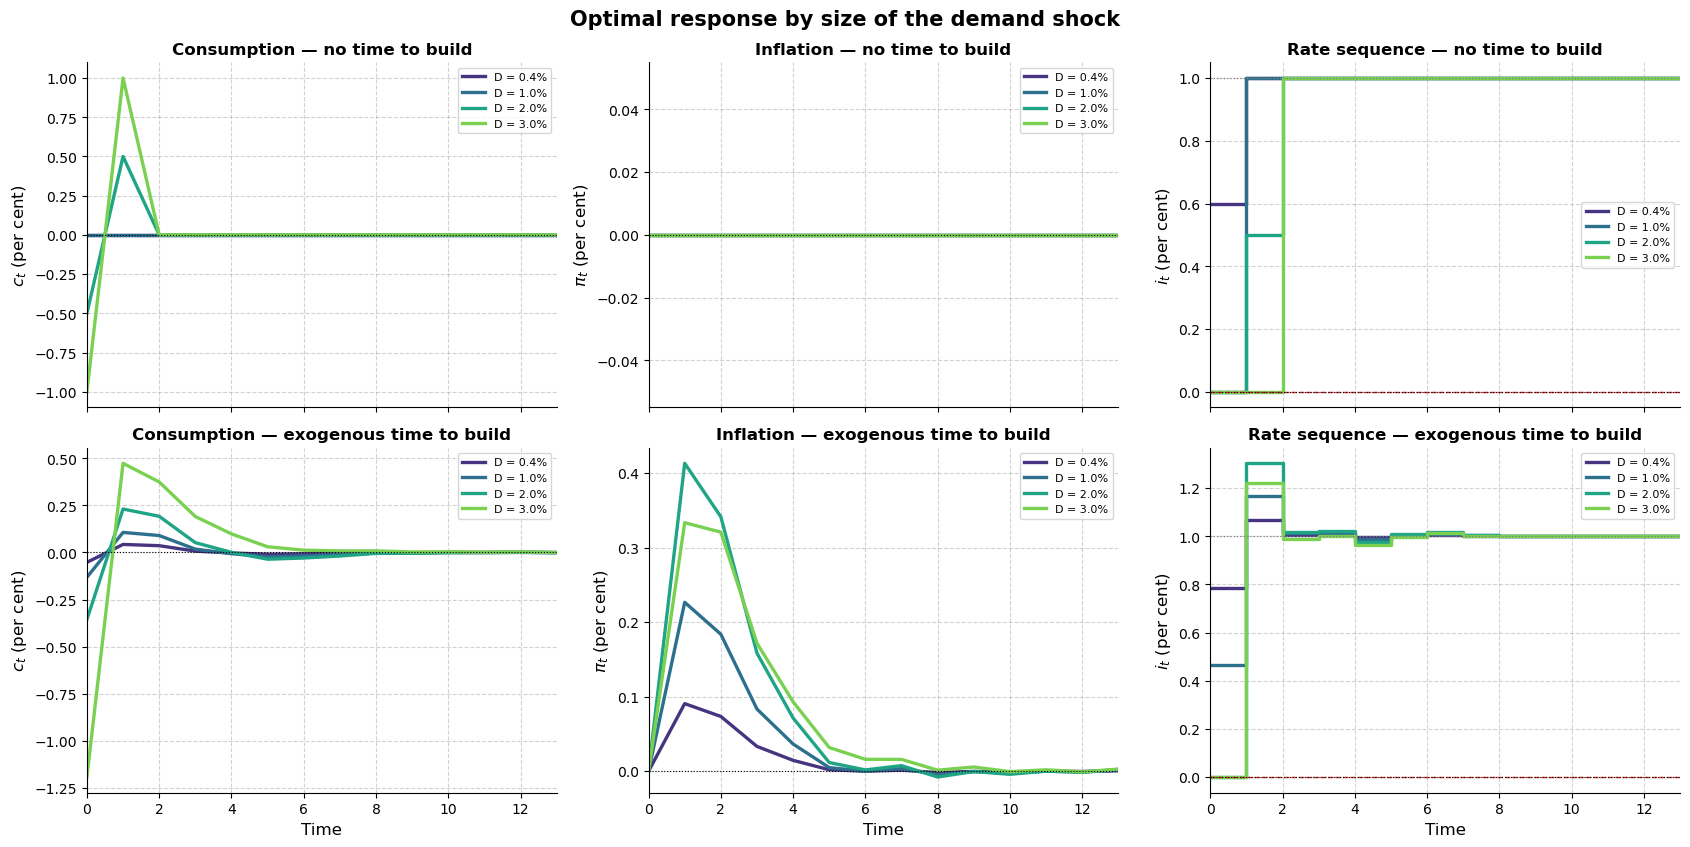

In [11]:
H = 14
t = np.arange(H)
colors = plt.cm.viridis(np.linspace(0.15, 0.8, len(D_SIZES)))

fig, axes = plt.subplots(2, 3, figsize=(17, 8.6), sharex=True)
for row, ttb in enumerate([False, True]):
    for D, col in zip(D_SIZES, colors):
        r, s = sweep[(ttb, D)]
        lab = f'D = {100*D:.1f}%'
        axes[row, 0].plot(t, 100 * s['c'][:H],  lw=2.4, color=col, label=lab)
        axes[row, 1].plot(t, 100 * s['pi'][:H], lw=2.4, color=col, label=lab)
        axes[row, 2].step(t, 100 * s['i'][:H], where='post', lw=2.4, color=col, label=lab)

    axes[row, 0].set_ylabel('$c_t$ (per cent)', fontsize=12)
    axes[row, 1].set_ylabel(r'$\pi_t$ (per cent)', fontsize=12)
    axes[row, 2].set_ylabel('$i_t$ (per cent)', fontsize=12)
    axes[row, 2].axhline(100 * rho, color='grey', lw=0.9, ls=':')
    axes[row, 2].axhline(0, color='C3', lw=1.0, ls='--')

    tag = 'no time to build' if not ttb else 'exogenous time to build'
    axes[row, 0].set_title(f'Consumption — {tag}', fontsize=12, weight='bold')
    axes[row, 1].set_title(f'Inflation — {tag}', fontsize=12, weight='bold')
    axes[row, 2].set_title(f'Rate sequence — {tag}', fontsize=12, weight='bold')

for ax in axes.ravel():
    ax.set_xlim(0, H - 1)
    ax.grid(True, linestyle='--', alpha=0.35, color='gray')
    ax.axhline(0, color='k', lw=0.8, ls=':')
    ax.legend(fontsize=8)
    ax.spines['top'].set_visible(False)
    ax.spines['right'].set_visible(False)
for ax in axes[1]:
    ax.set_xlabel('Time', fontsize=12)

fig.suptitle('Optimal response by size of the demand shock', fontsize=15, weight='bold')
plt.tight_layout()
plt.savefig('../semi_endo_demand_sizes.png', dpi=150, bbox_inches='tight')
plt.show()

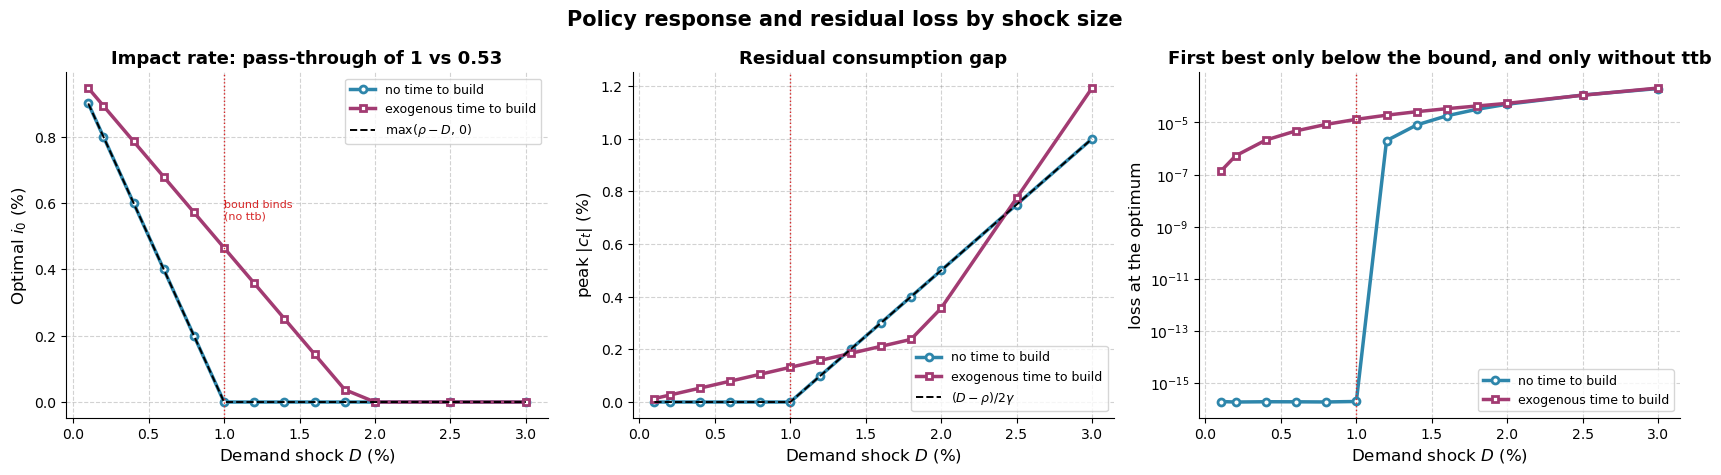

In [12]:
fig, axes = plt.subplots(1, 3, figsize=(17, 4.8))
x = 100 * D_GRID

ax = axes[0]
ax.plot(x, [100 * sweep[(False, D)][0][0] for D in D_GRID], color='#2E86AB', lw=2.5,
        marker='o', markersize=5, markerfacecolor='white', markeredgewidth=2,
        label='no time to build')
ax.plot(x, [100 * sweep[(True,  D)][0][0] for D in D_GRID], color='#A23B72', lw=2.5,
        marker='s', markersize=5, markerfacecolor='white', markeredgewidth=2,
        label='exogenous time to build')
ax.plot(x, np.maximum(100 * (rho - D_GRID), 0), 'k--', lw=1.4, label=r'$\max(\rho-D,\,0)$')
ax.axvline(100 * rho, color='C3', lw=1.0, ls=':')
ax.annotate('bound binds\n(no ttb)', xy=(100 * rho, 0.55), fontsize=8, color='C3')
ax.set_xlabel('Demand shock $D$ (%)', fontsize=12)
ax.set_ylabel('Optimal $i_0$ (%)', fontsize=12)
ax.set_title('Impact rate: pass-through of 1 vs 0.53', fontsize=13, weight='bold')
ax.legend(fontsize=9)

ax = axes[1]
ax.plot(x, [100 * np.max(np.abs(sweep[(False, D)][1]['c'])) for D in D_GRID],
        color='#2E86AB', lw=2.5, marker='o', markersize=5, markerfacecolor='white',
        markeredgewidth=2, label='no time to build')
ax.plot(x, [100 * np.max(np.abs(sweep[(True,  D)][1]['c'])) for D in D_GRID],
        color='#A23B72', lw=2.5, marker='s', markersize=5, markerfacecolor='white',
        markeredgewidth=2, label='exogenous time to build')
ax.plot(x, 100 * np.maximum(D_GRID - rho, 0) / (2 * gamma), 'k--', lw=1.4,
        label=r'$(D-\rho)/2\gamma$')
ax.axvline(100 * rho, color='C3', lw=1.0, ls=':')
ax.set_xlabel('Demand shock $D$ (%)', fontsize=12)
ax.set_ylabel(r'peak $|c_t|$ (%)', fontsize=12)
ax.set_title('Residual consumption gap', fontsize=13, weight='bold')
ax.legend(fontsize=9)

ax = axes[2]
ax.semilogy(x, [max(np.sum(sweep[(False, D)][1]['c']**2) +
                    np.sum(sweep[(False, D)][1]['pi']**2), 1e-18) for D in D_GRID],
            color='#2E86AB', lw=2.5, marker='o', markersize=5, markerfacecolor='white',
            markeredgewidth=2, label='no time to build')
ax.semilogy(x, [np.sum(sweep[(True, D)][1]['c']**2) +
                np.sum(sweep[(True, D)][1]['pi']**2) for D in D_GRID],
            color='#A23B72', lw=2.5, marker='s', markersize=5, markerfacecolor='white',
            markeredgewidth=2, label='exogenous time to build')
ax.axvline(100 * rho, color='C3', lw=1.0, ls=':')
ax.set_xlabel('Demand shock $D$ (%)', fontsize=12)
ax.set_ylabel('loss at the optimum', fontsize=12)
ax.set_title('First best only below the bound, and only without ttb',
             fontsize=13, weight='bold')
ax.legend(fontsize=9)

for ax in axes:
    ax.grid(True, linestyle='--', alpha=0.35, color='gray')
    ax.spines['top'].set_visible(False)
    ax.spines['right'].set_visible(False)

fig.suptitle('Policy response and residual loss by shock size', fontsize=15, weight='bold')
plt.tight_layout()
plt.savefig('../semi_endo_demand_sizes_policy.png', dpi=150, bbox_inches='tight')
plt.show()

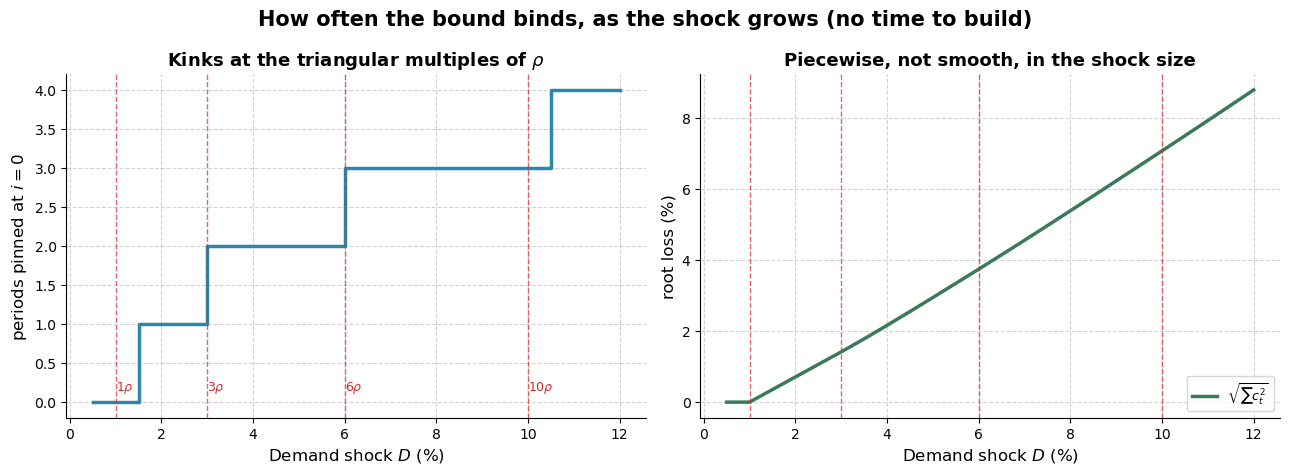

In [13]:
fig, (ax1, ax2) = plt.subplots(1, 2, figsize=(13, 4.8))
xk = 100 * D_KINK

ax1.step(xk, at_bound, where='post', color='#2E86AB', lw=2.5)
for k in [1, 3, 6, 10]:
    ax1.axvline(100 * k * rho, color='C3', lw=1.0, ls='--', alpha=0.7)
    ax1.annotate(rf'${k}\rho$', xy=(100 * k * rho, 0.15), fontsize=9, color='C3')
ax1.set_xlabel('Demand shock $D$ (%)', fontsize=12)
ax1.set_ylabel('periods pinned at $i=0$', fontsize=12)
ax1.set_title('Kinks at the triangular multiples of $\\rho$', fontsize=13, weight='bold')

# the one-period-at-the-bound closed form, extrapolated past where it is valid
loss_k = np.array([np.sum(kink[D][1]['c']**2) for D in D_KINK])
extrap = np.maximum(D_KINK - rho, 0) / np.sqrt(2) / gamma

ax2.plot(xk, 100 * loss_k ** 0.5, color='#3B7A57', lw=2.5, label=r'$\sqrt{\sum c_t^2}$')
ax2.plot(xk, 100 * extrap, 'k--', lw=1.4,
         label=r'$(D-\rho)/\sqrt{2}\gamma$, valid to $3\rho$')
for k in [1, 3, 6, 10]:
    ax2.axvline(100 * k * rho, color='C3', lw=1.0, ls='--', alpha=0.7)
ax2.set_xlabel('Demand shock $D$ (%)', fontsize=12)
ax2.set_ylabel('root loss (%)', fontsize=12)
ax2.set_title('Extrapolating the first segment understates the cost',
              fontsize=13, weight='bold')
ax2.legend(fontsize=9, loc='upper left')

for ax in (ax1, ax2):
    ax.grid(True, linestyle='--', alpha=0.35, color='gray')
    ax.spines['top'].set_visible(False)
    ax.spines['right'].set_visible(False)

fig.suptitle('How often the bound binds, as the shock grows (no time to build)',
             fontsize=15, weight='bold')
plt.tight_layout()
plt.savefig('../semi_endo_demand_sizes_bound.png', dpi=150, bbox_inches='tight')
plt.show()

## Summary

- The model is log-linear, so the **fixed-rate** response carries no information about size:
  $c_0=-D/\gamma$ exactly and everything else is zero, with or without time to build. Any
  size-dependence in this framework is a property of the *policy problem*, not of the shock.
- **Without time to build** the discount block is identically one, so $a^{nat}=d=\pi\equiv0$
  whatever policy does and the loss is just $\sum_t x_t^2$. The planner zeroes it exactly with
  $i_0=\rho-D$ — pass-through of one — until $D=\rho=1\%$. Above that, $i_0=0$ and the shortfall
  is split evenly across periods 0 and 1, giving peak $|c|=(D-\rho)/2\gamma$ and loss
  $(D-\rho)^2/2\gamma^2$, exact up to $D=3\rho$.
- **The bound bites repeatedly.** Thresholds at $D/\rho=1,3,6$ and just above $10$ each pull one
  more period to zero. The loss is therefore piecewise quadratic in shock size, so extrapolating
  a small-shock policy rule to a large shock understates what the planner has to do.
- **Time to build roughly halves the pass-through**, to $\lambda=0.535$, and the relation stays
  linear in $D$ to well under a basis point. Cutting the rate now moves firms' discounting and
  hence prices, so stimulus is no longer free and the planner buys less of it. Two consequences
  pull in opposite directions: the first best is unattainable at *any* size, but the bound is not
  reached until $D=1.87\%$ instead of $1\%$.

**Caveats.** The natural rate is left at $\rho$ plus the shifter, as in `new_fixed.ipynb`, rather
than picking up the $\gamma\Delta y^n$ term used in `planner_adjusted_consumption.ipynb`. The
shock is one period at $t=0$; `zeta_demand_shock.ipynb` treats persistence and the preference
shifter as a primitive, and finds the opposite comparative static — persistence *raises* the
impact natural rate and so makes the bound bind less. The inflation weight is 1.0 throughout;
at weight 0 the objective becomes the planner's, and section 6 of `new_fixed.ipynb` sweeps it.